# 06. Evaluación inicial y evidencia conservada

Leer la evaluación inicial y mostrar separadamente la evidencia definitiva, sin mezclar sus archivos.

**Dataset principal:** `data/nuevo_dataset/cardio_train.csv`. Este cuaderno no ejecuta entrenamientos. Los resultados históricos se leen de archivos conservados; no se sustituyen por nuevas ejecuciones.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/nuevo_dataset/cardio_train.csv").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.experimento import (
    ORIGINAL, RESULTADOS, VARIABLES, NOMBRES, cargar_datos, reglas_calidad,
    cargar_metricas, comparar_ejecuciones, tabla_configuracion, verificar_configuracion,
    construir_cnn, tabla_modelo, dibujar_arquitectura, guardar_figura_nueva,
    importancia_guardada, resumen_dataset, verificar_predicciones, tensorflow_disponible,
)

In [2]:
display(comparar_ejecuciones())
print("Métricas iniciales:")
display(cargar_metricas("metricas_nueva_cnn.csv"))
print("Métricas definitivas:")
display(cargar_metricas("metricas_evaluacion.csv"))

Métricas iniciales:
Métricas definitivas:


,Protocolo,Entrenamiento,Validación,Prueba,Épocas,Parámetros,Accuracy,Precision,Recall,F1,ROC-AUC
0,StandardScaler,10500,2250,2250,44,34529,0.712444,0.716141,0.693621,0.704701,0.775738
1,MinMaxScaler,10200,2550,2250,66,34529,0.731111,0.732601,0.718778,0.725624,0.788458


,Metrica,Valor
0,Accuracy,0.712444
1,Precision,0.716141
2,Recall,0.693621
3,F1-score,0.704701
4,ROC-AUC,0.775738


,Metrica,Valor
0,Accuracy,0.731111
1,Precision,0.732601
2,Recall,0.718778
3,F1-score,0.725624
4,ROC-AUC,0.788458


## Ejecución inicial: StandardScaler
Las figuras con sufijo `_nueva_cnn` pertenecen a esta ejecución. Su reporte de clasificación permanece en el notebook original respaldado; no se guardó un archivo de predicciones independiente para reconstruirlo.

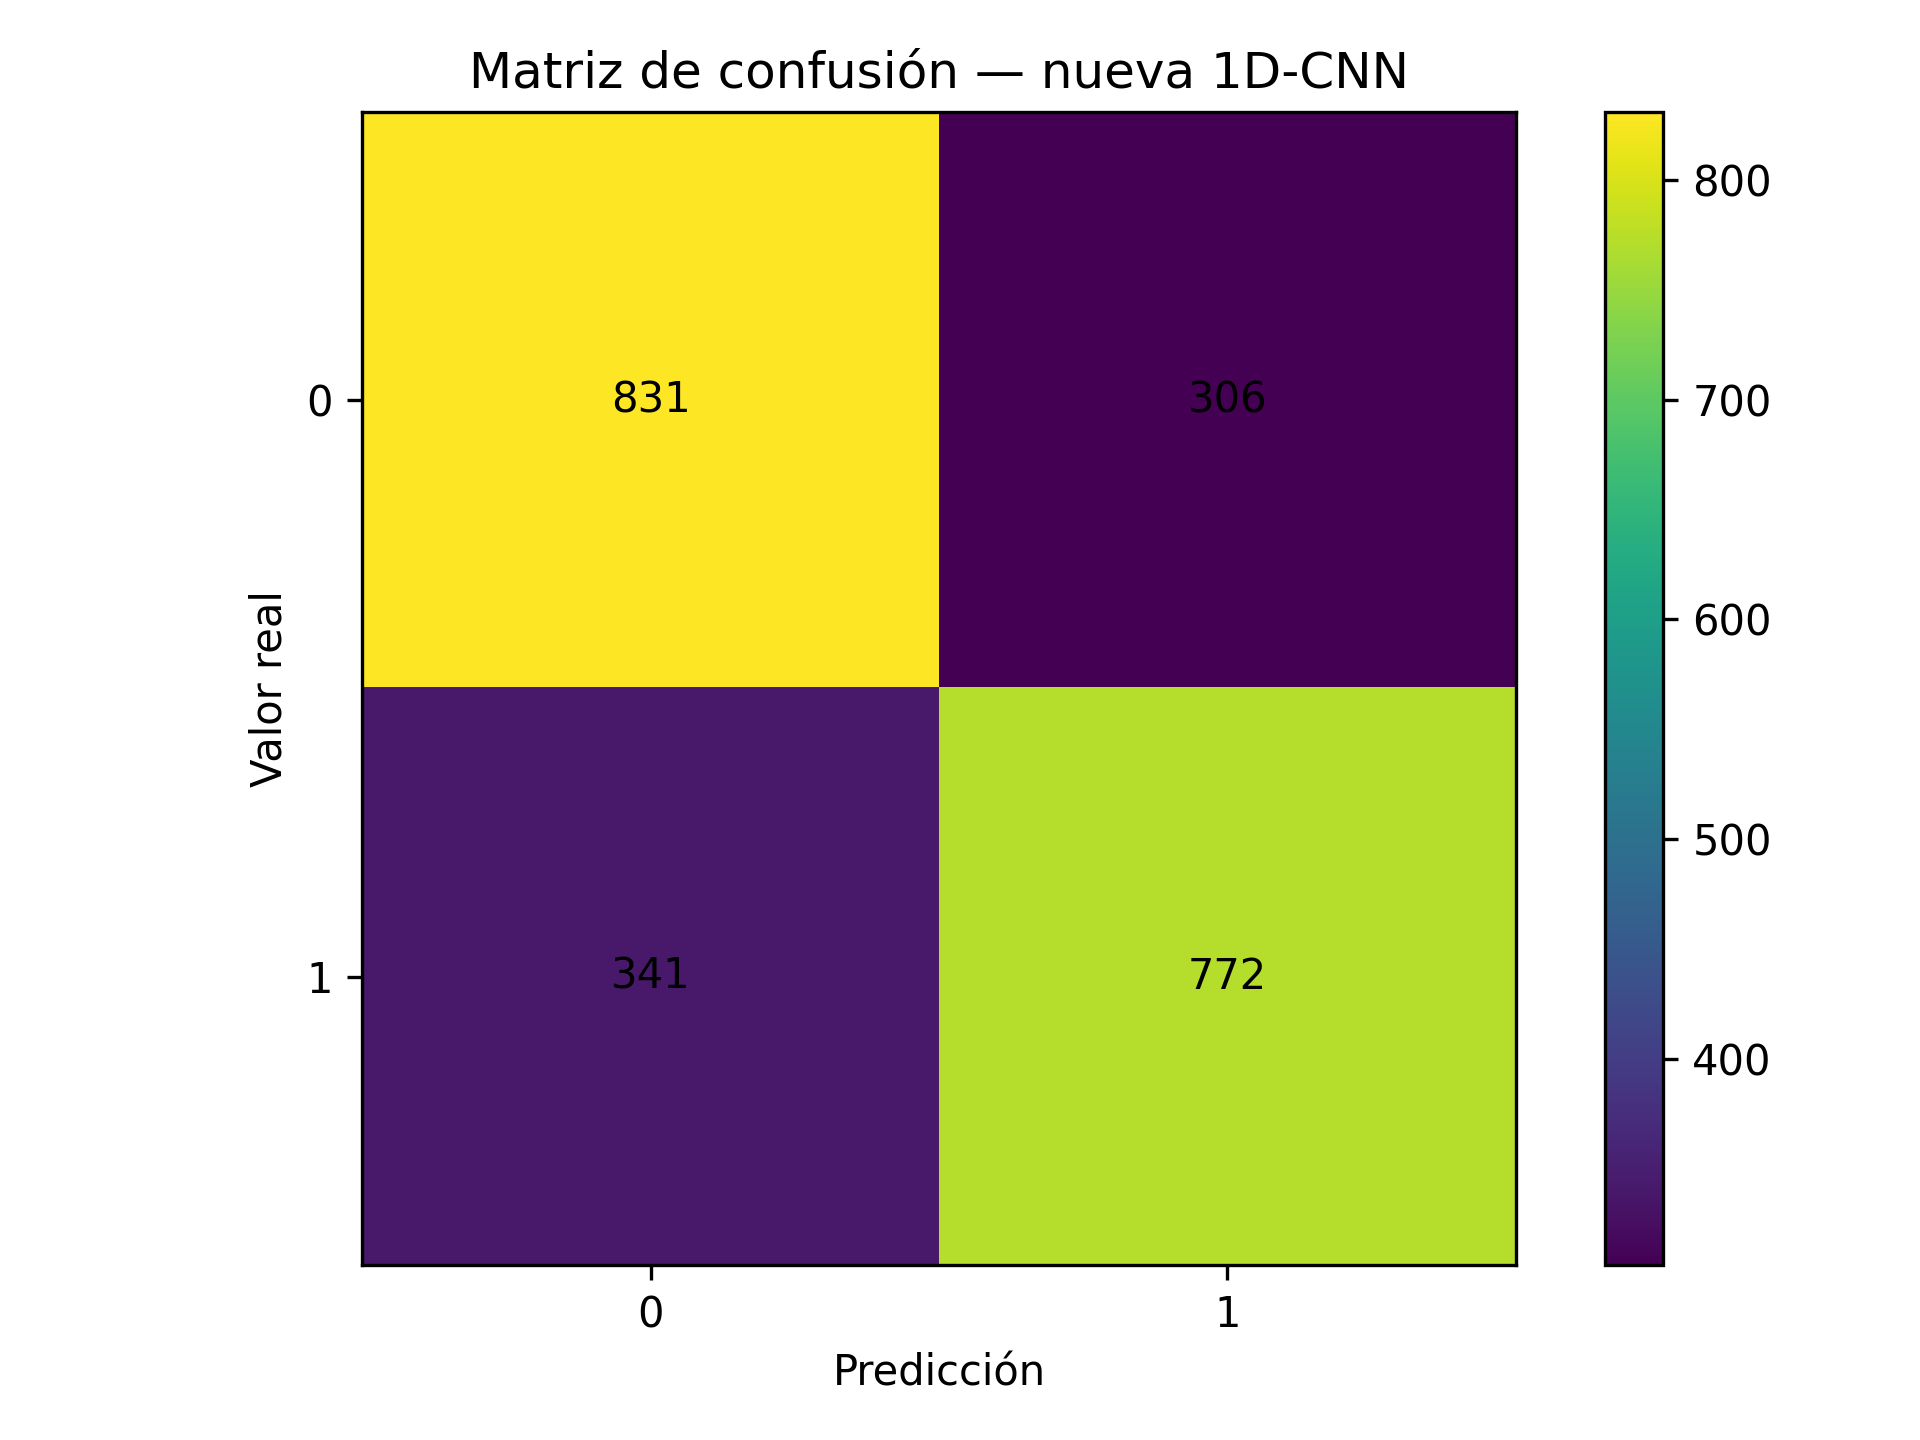

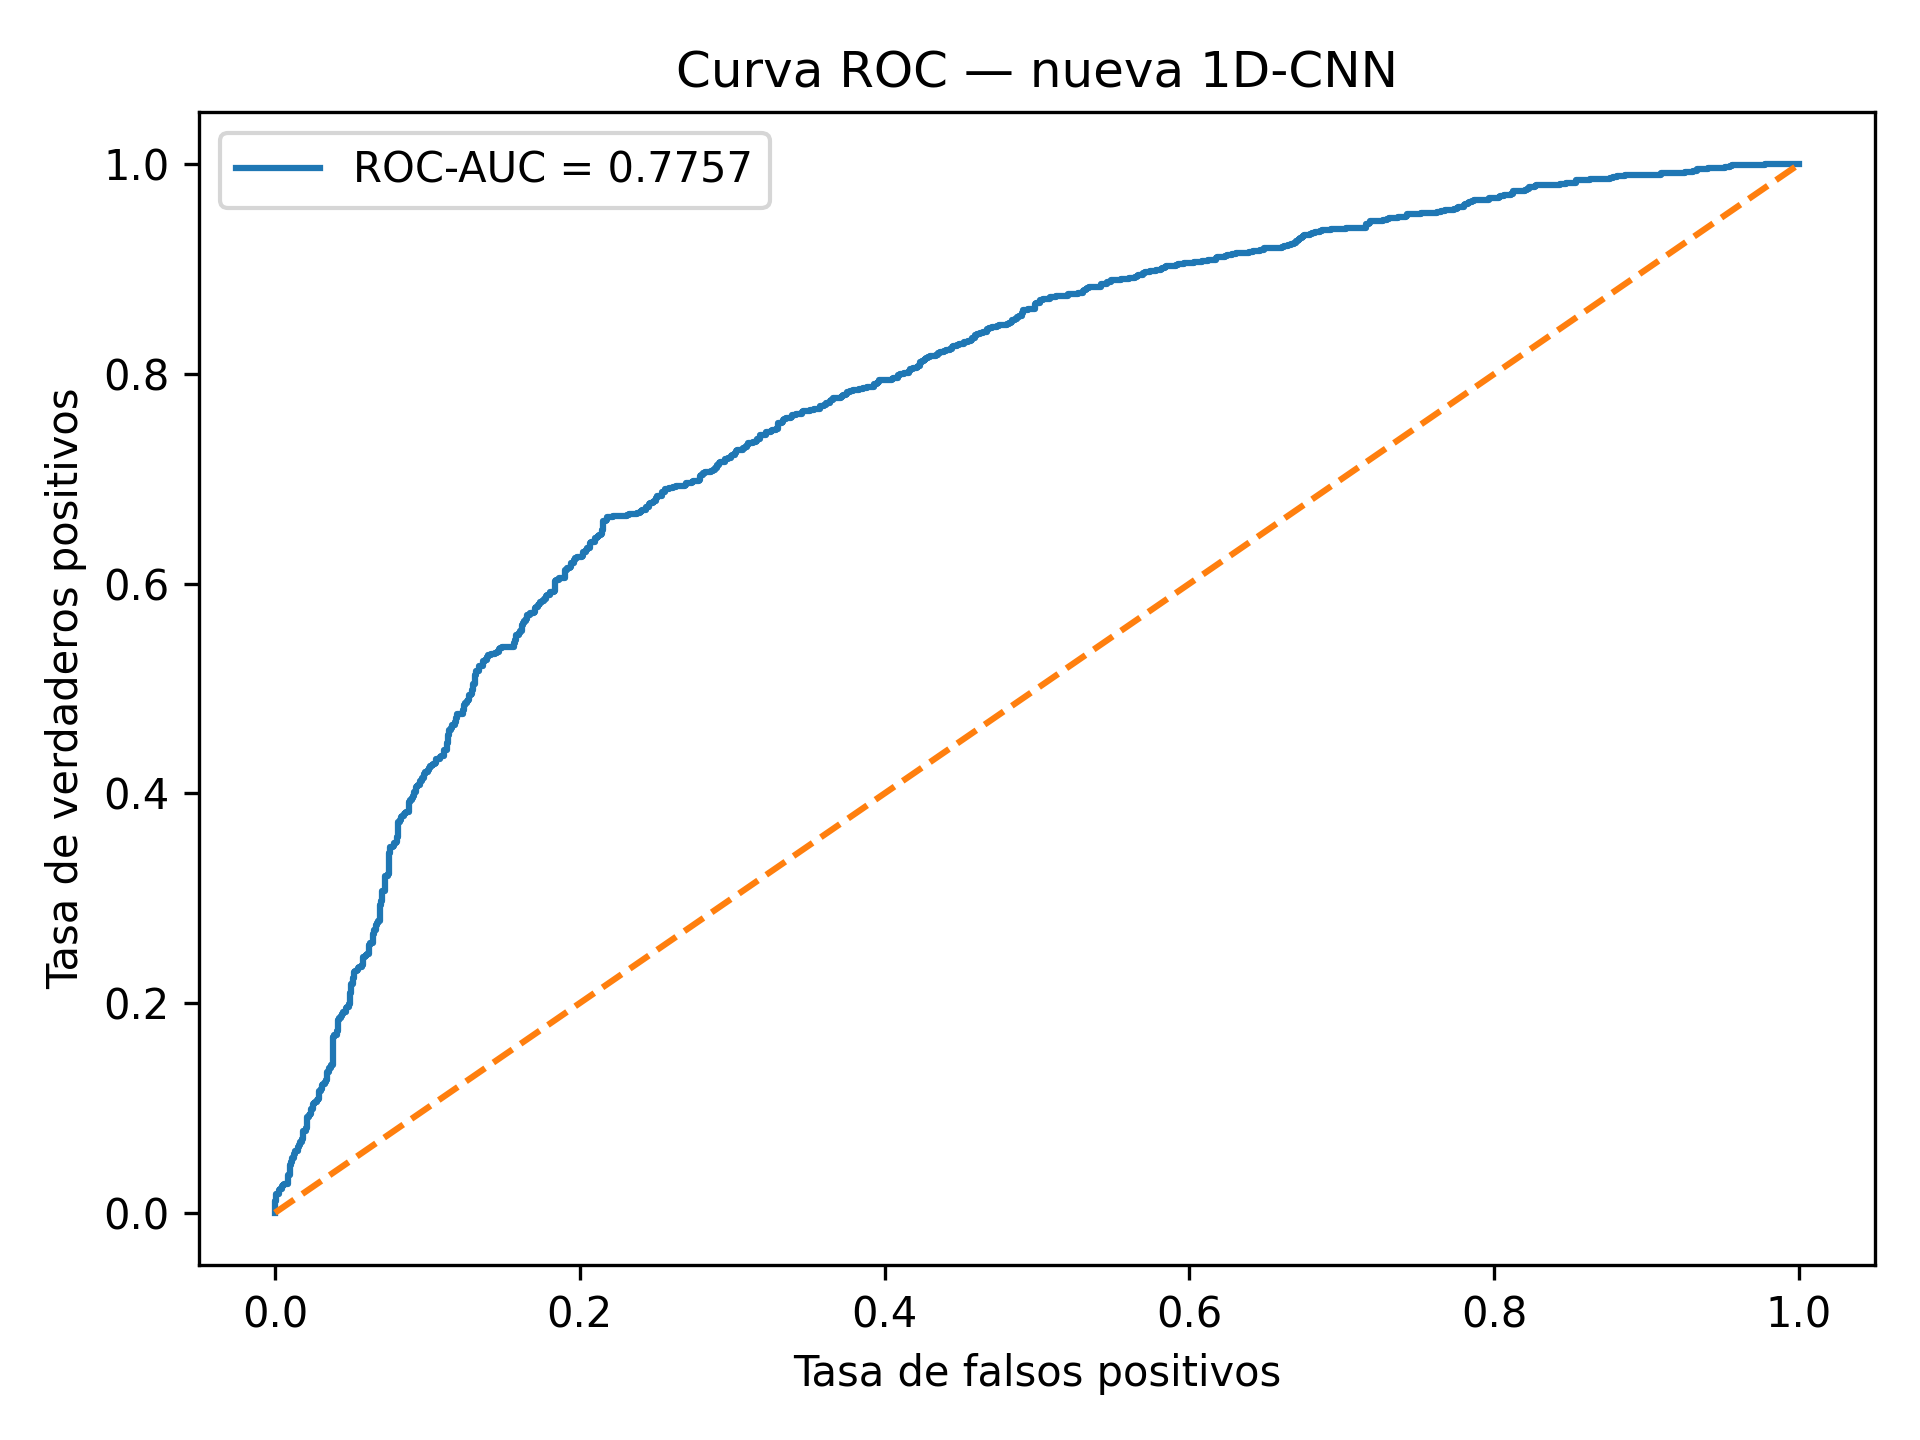

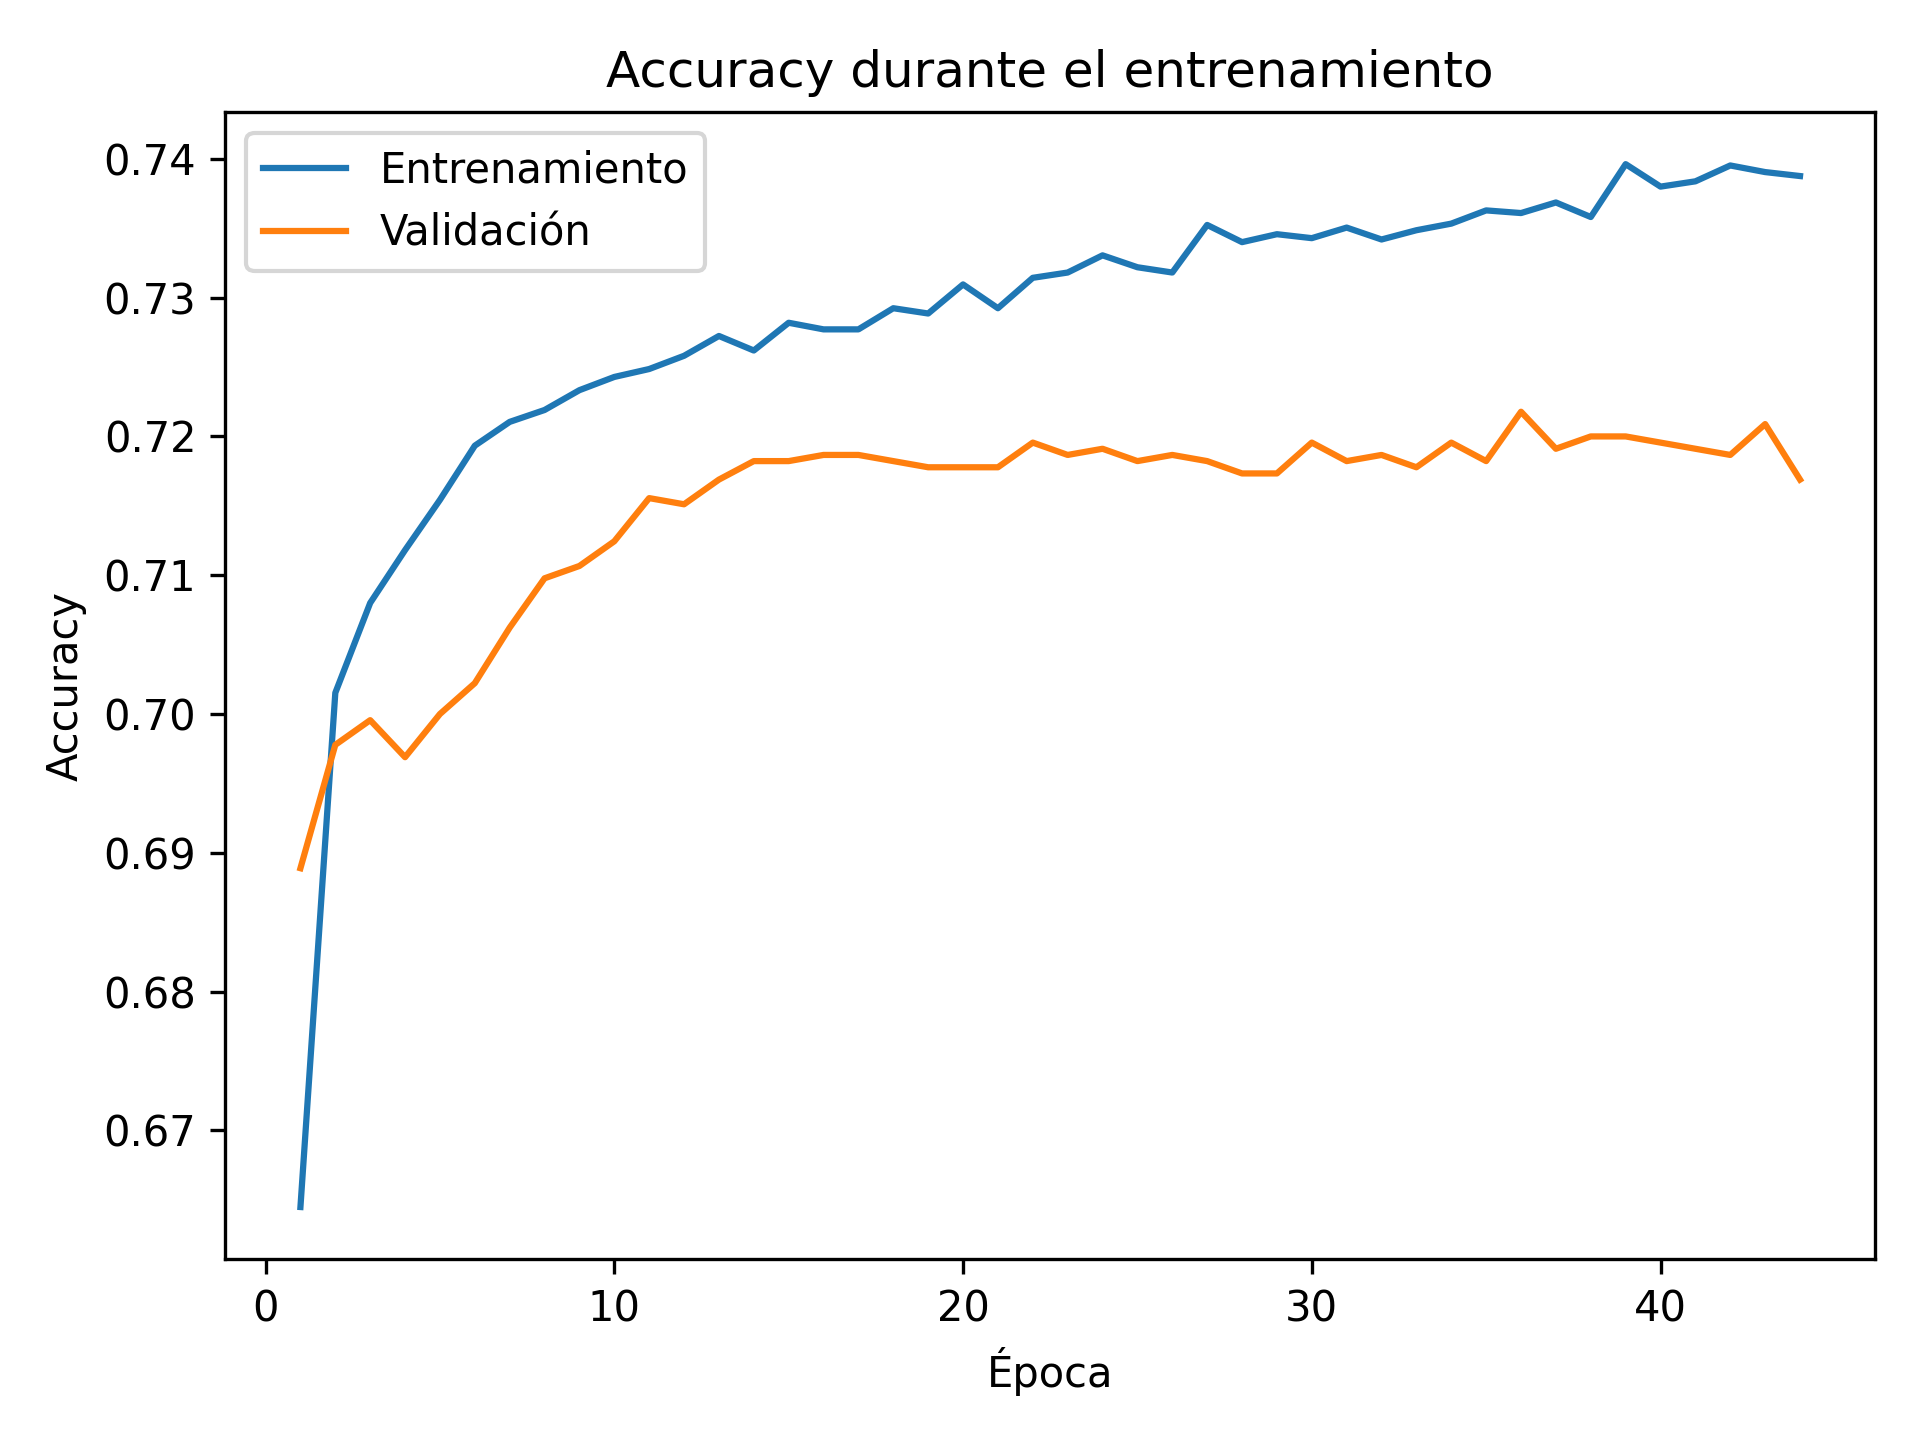

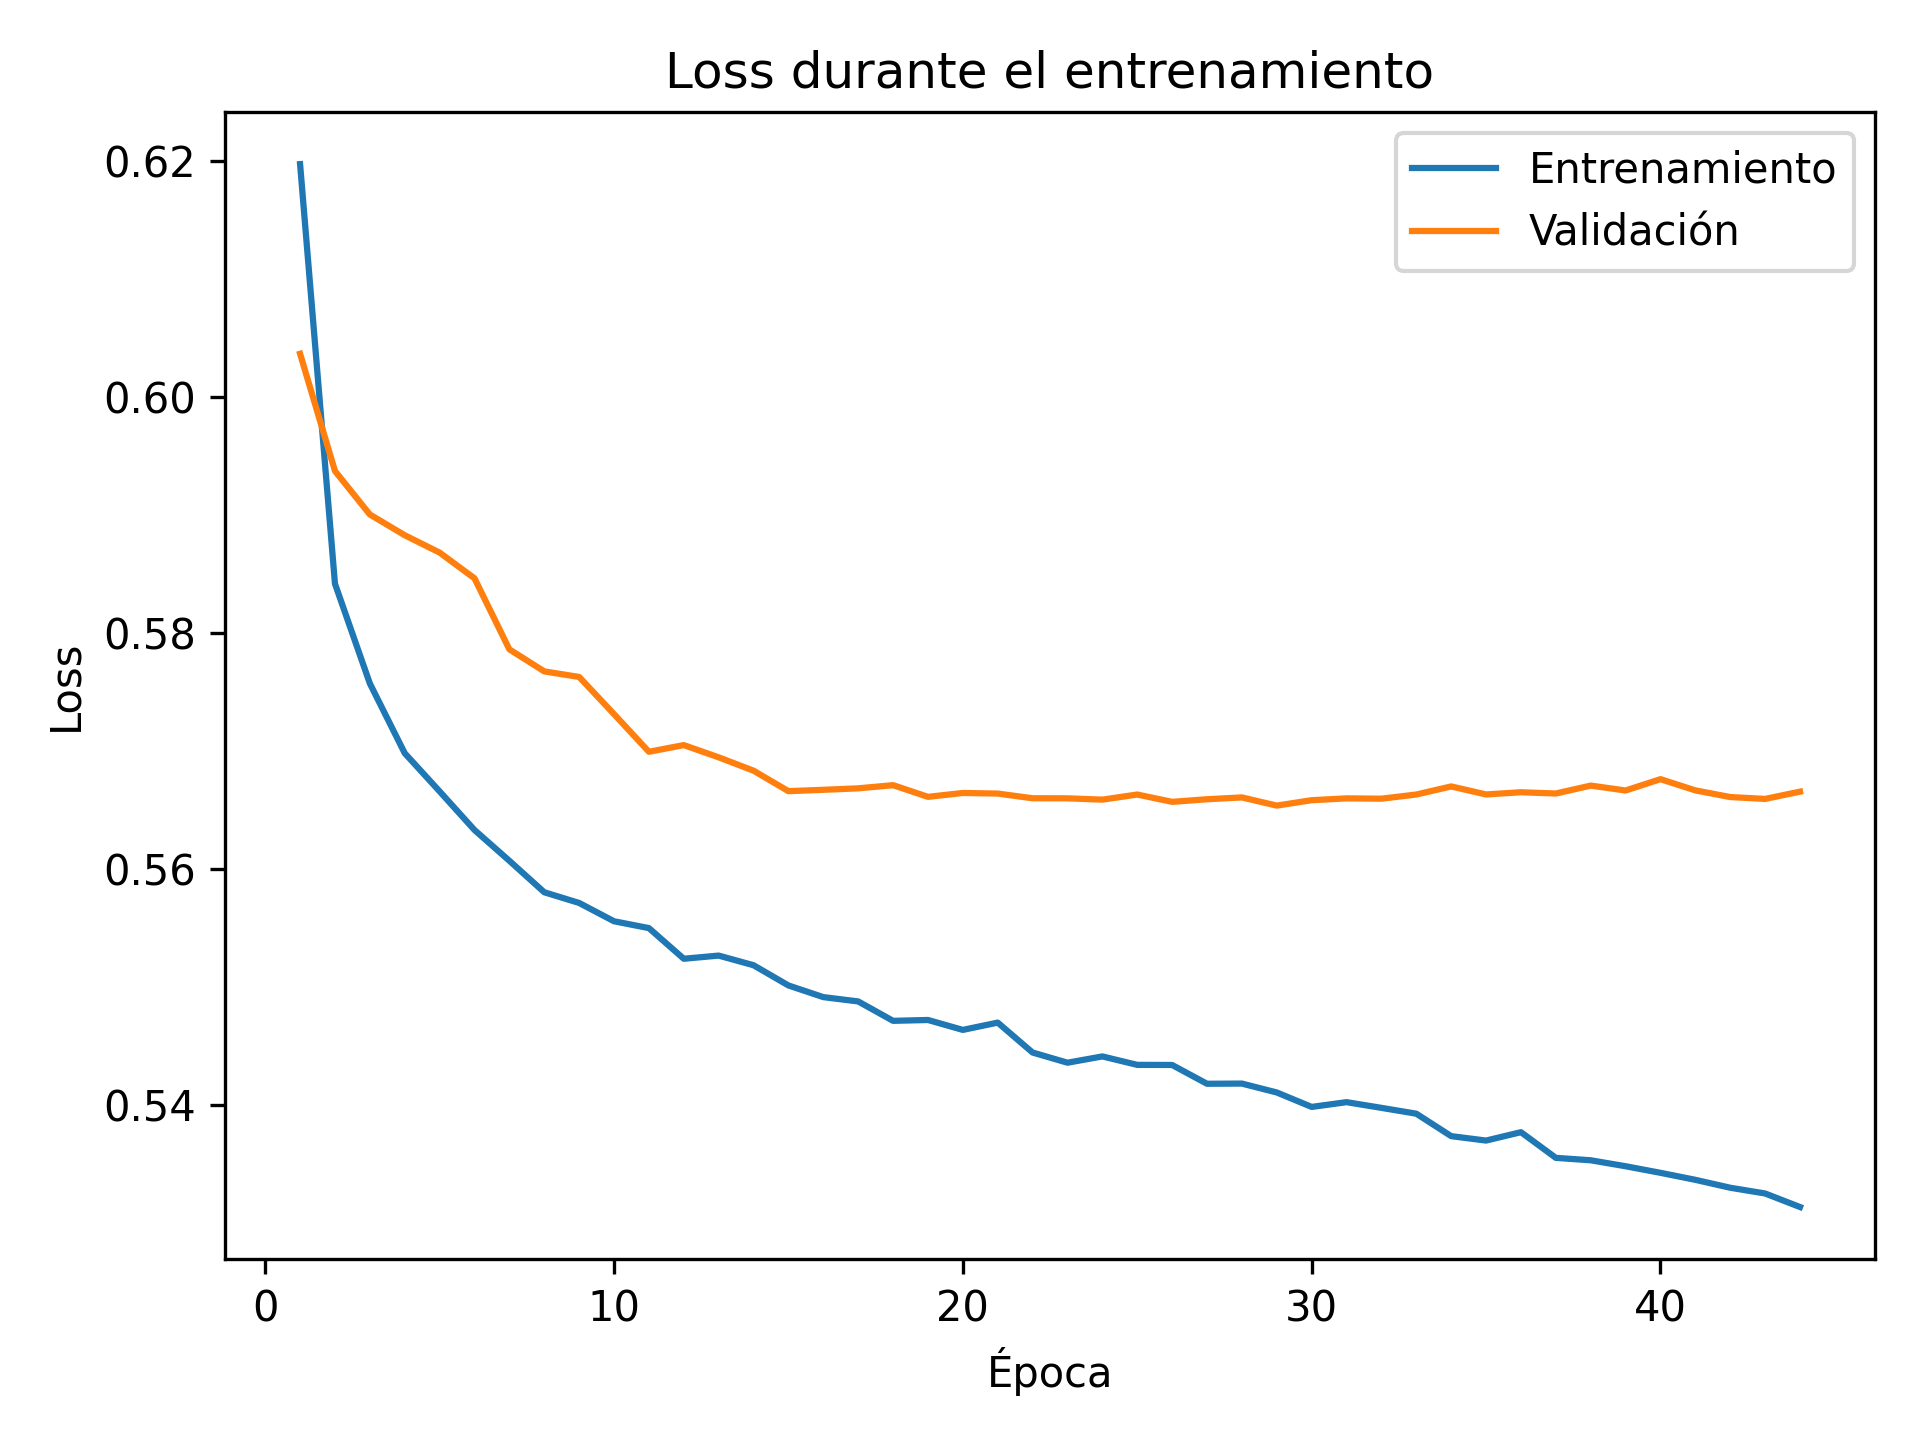

In [3]:
for nombre in ["matriz_confusion_nueva_cnn.png", "curva_roc_nueva_cnn.png", "curva_accuracy_nueva_cnn.png", "curva_loss_nueva_cnn.png"]:
    display(Image(filename=str(RESULTADOS / "figuras" / nombre)))

## Ejecución definitiva: MinMaxScaler
Las figuras sin ese sufijo, el reporte de clasificación y los tres archivos de predicciones corresponden a la ejecución definitiva. Se recalculan únicamente las métricas desde las predicciones guardadas para comprobar su coherencia, sin inferencia ni entrenamiento.

                precision    recall  f1-score   support

Sin enfermedad     0.7297    0.7432    0.7364      1137
Con enfermedad     0.7326    0.7188    0.7256      1113

      accuracy                         0.7311      2250
     macro avg     0.7312    0.7310    0.7310      2250
  weighted avg     0.7311    0.7311    0.7311      2250



,Metrica,Valor
0,Accuracy,0.731111
1,Precision,0.732601
2,Recall,0.718778
3,F1-score,0.725624
4,ROC-AUC,0.788458


,Predicho 0,Predicho 1
Real 0,845,292
Real 1,313,800


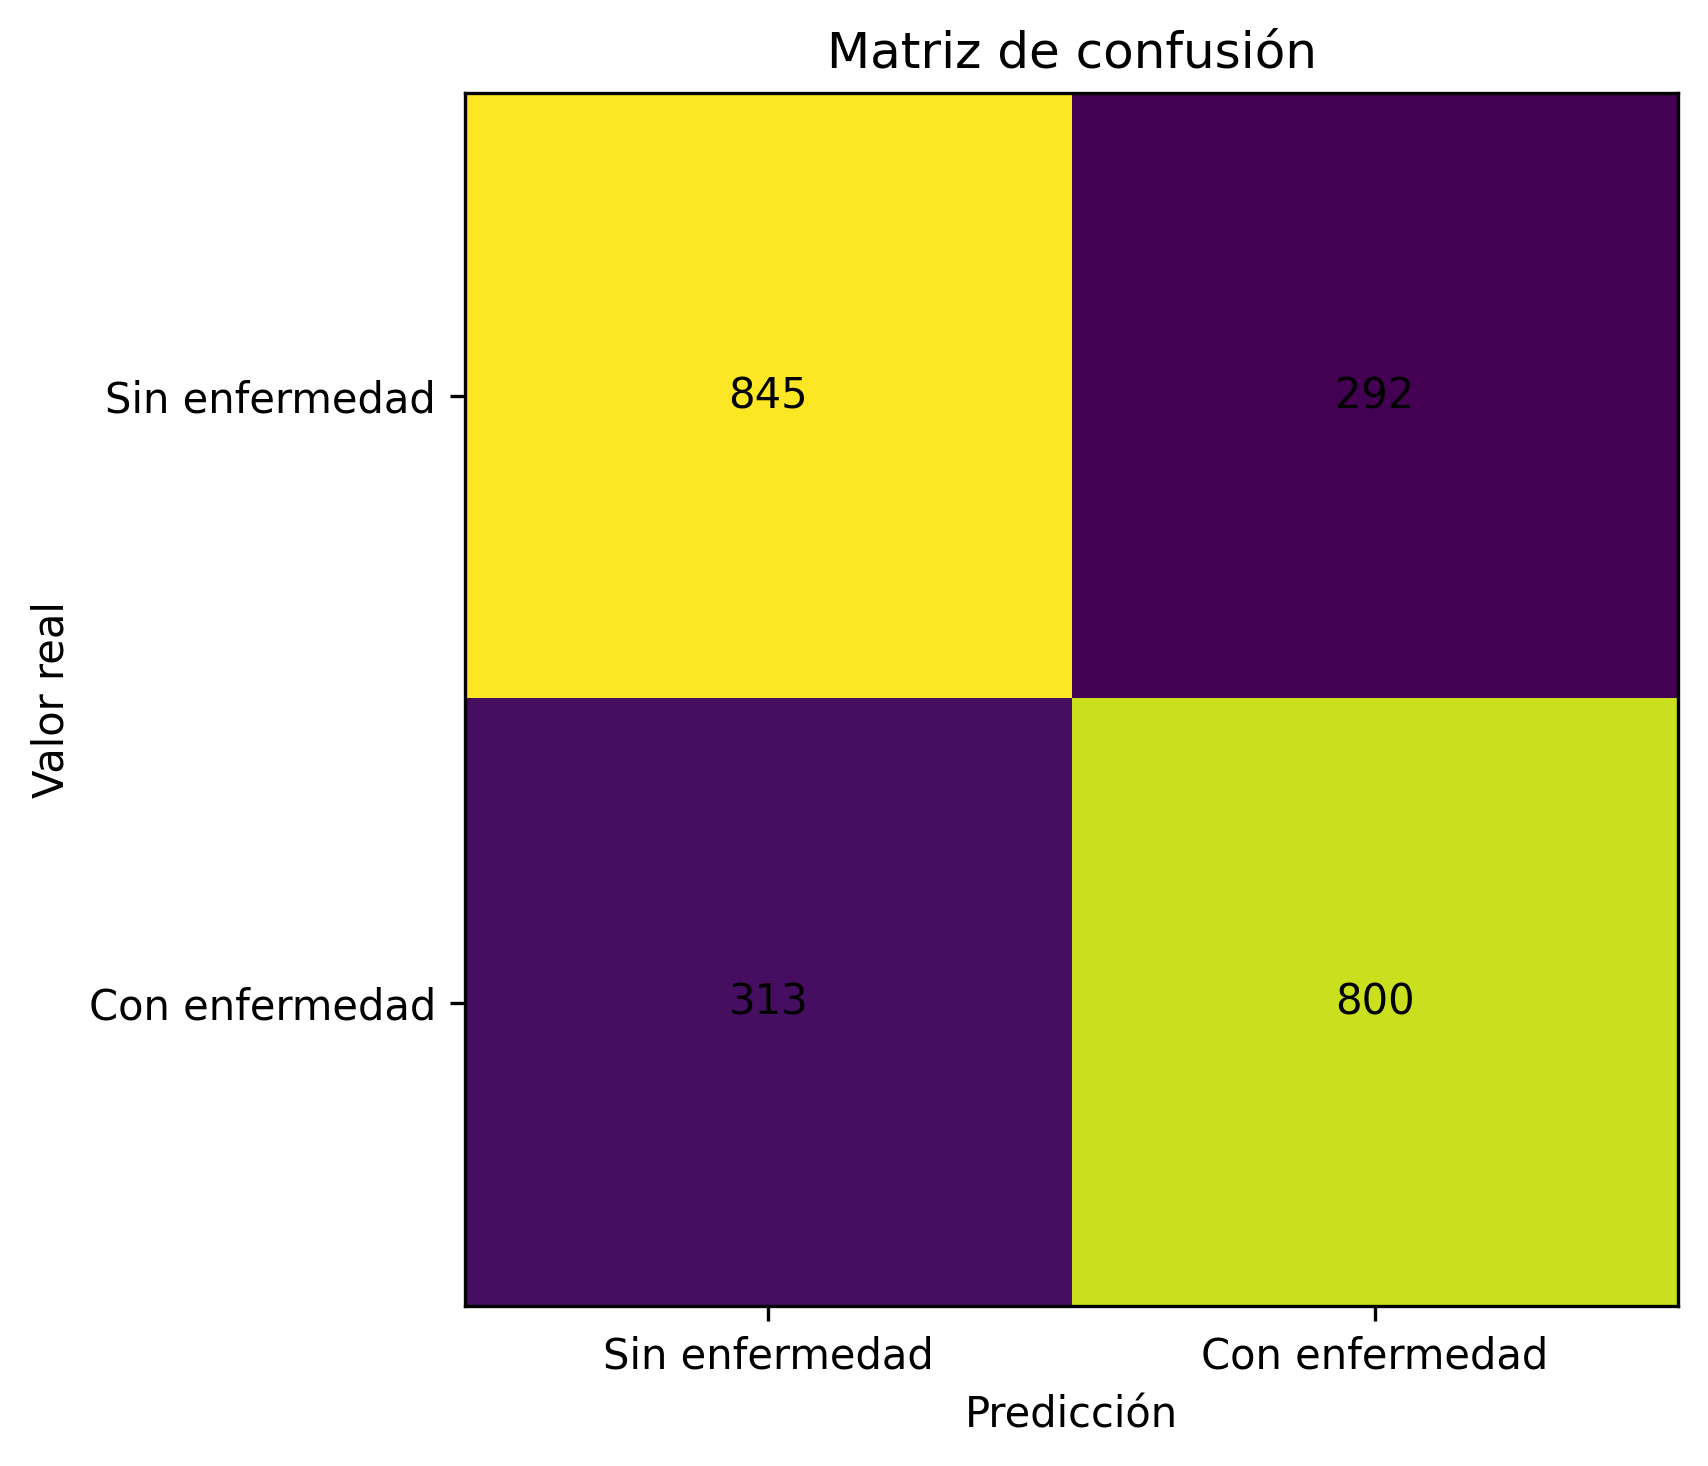

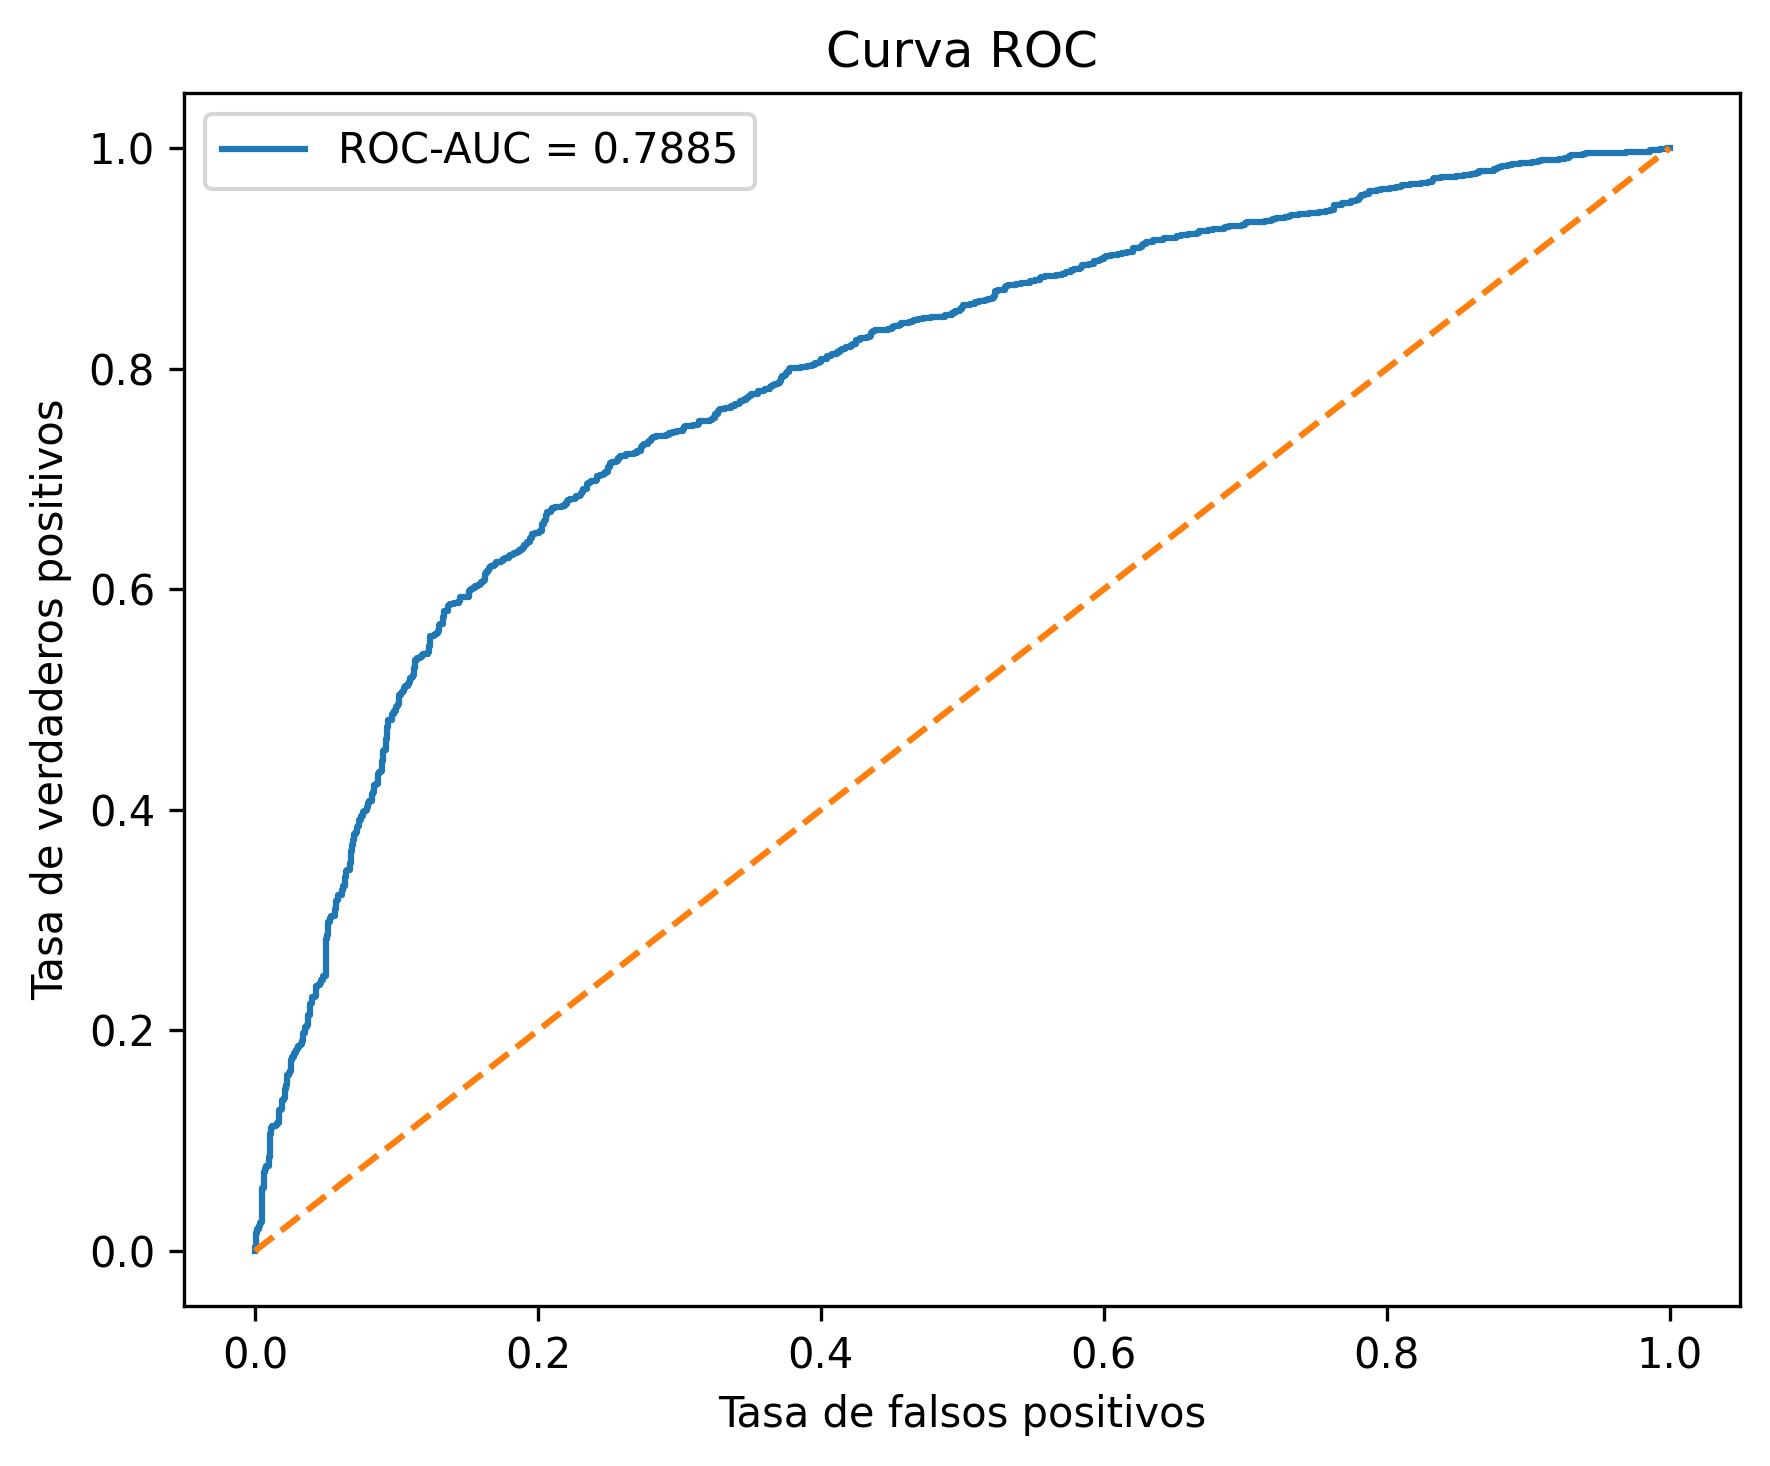

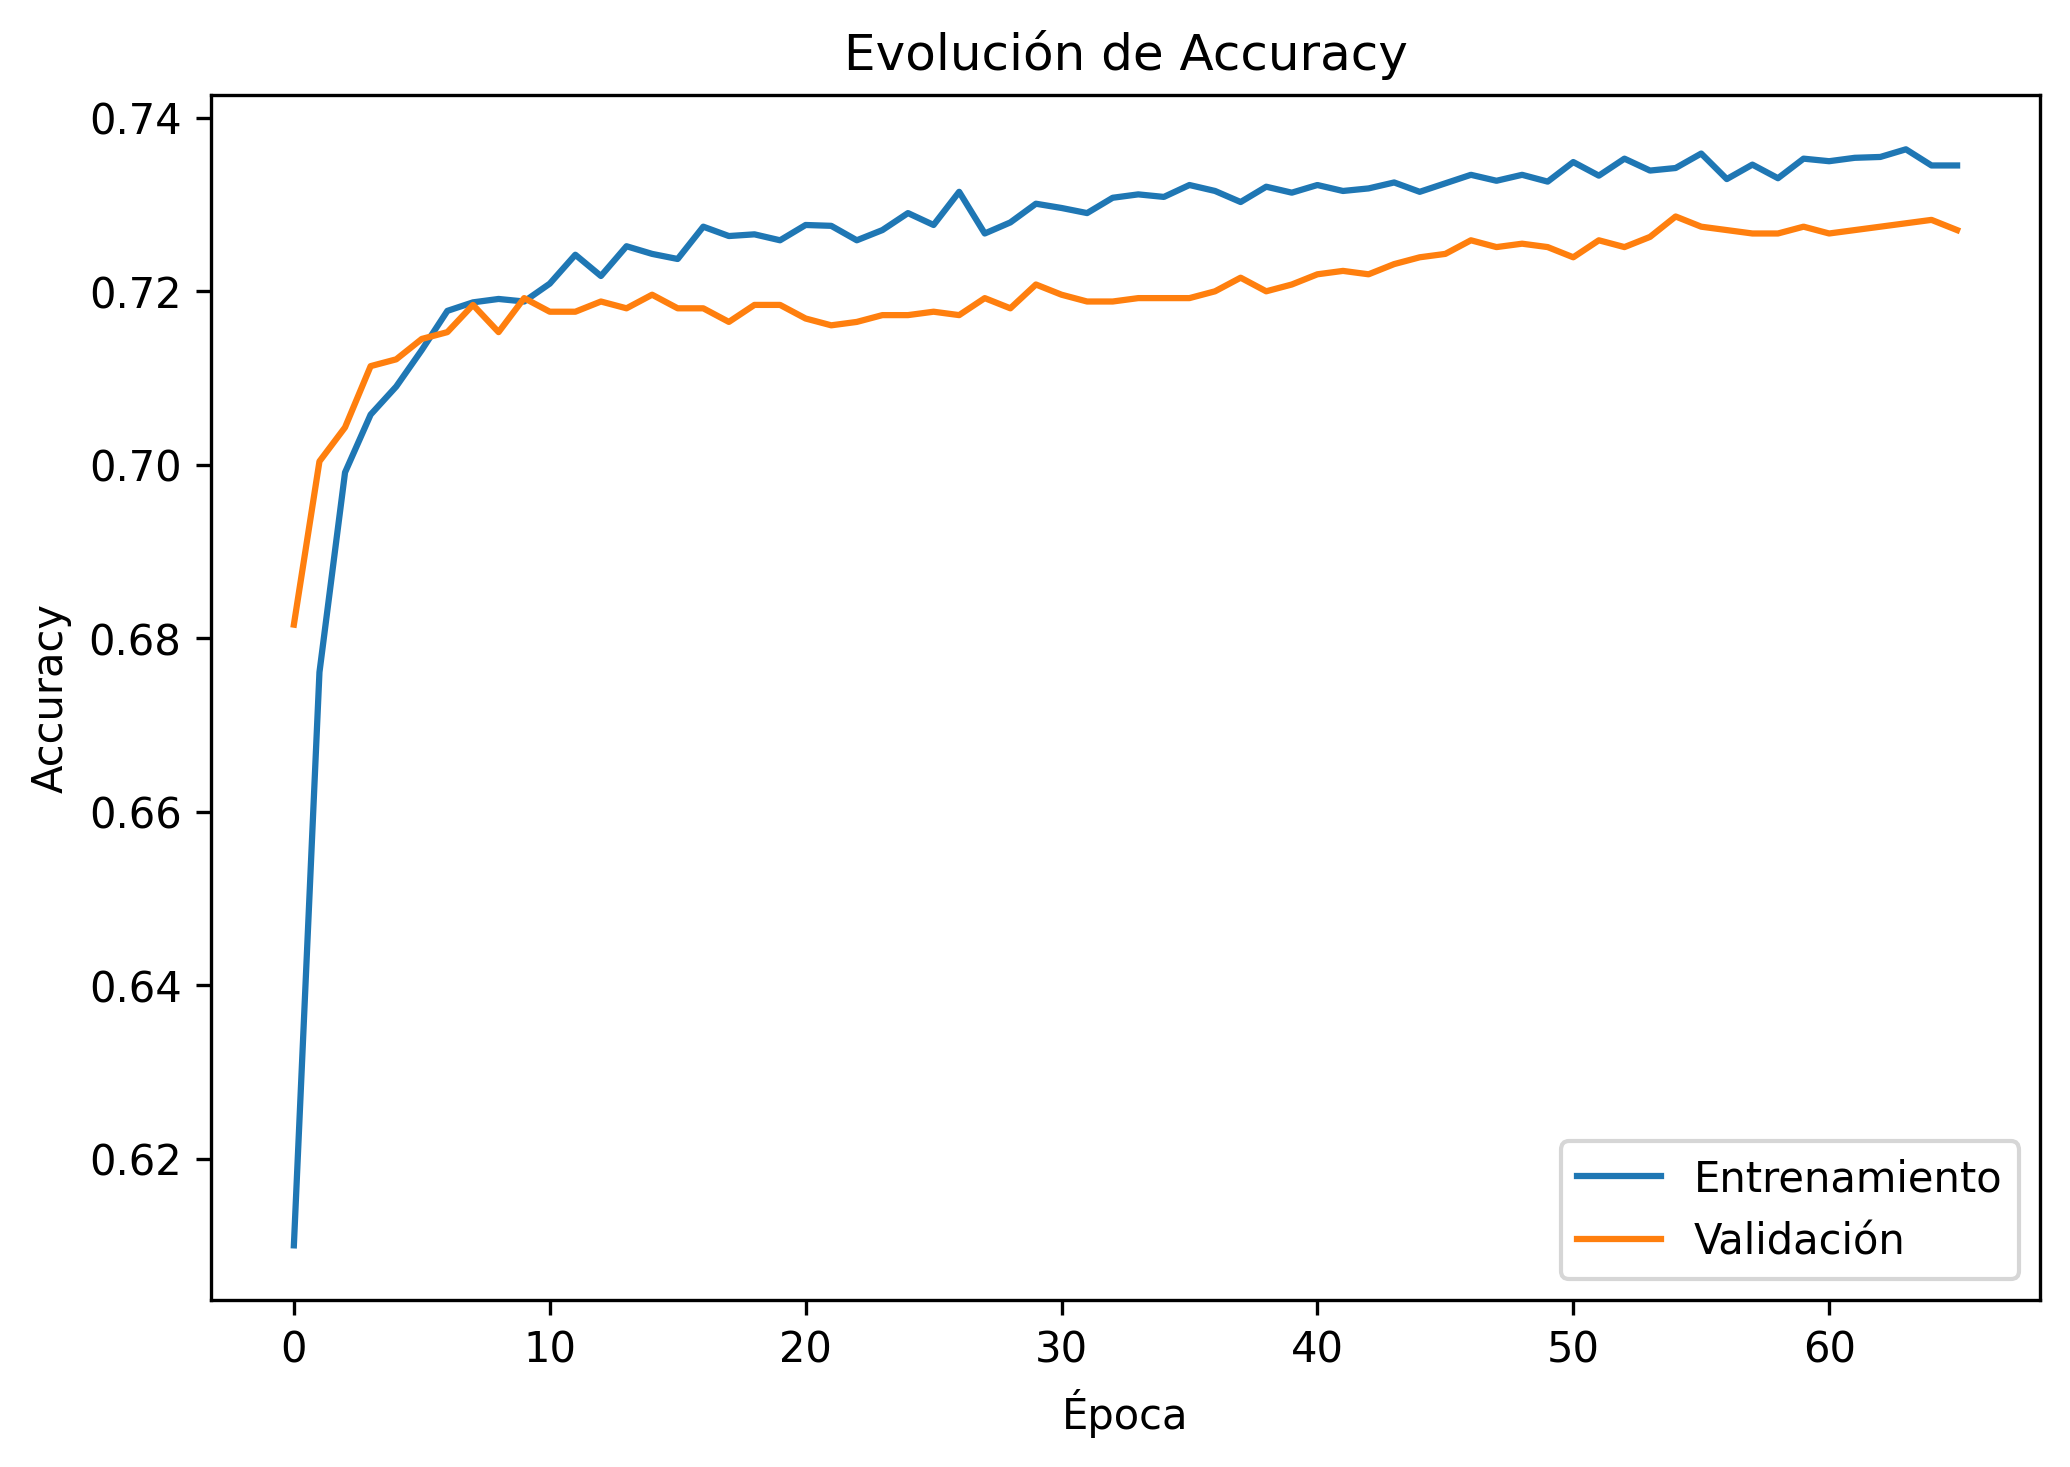

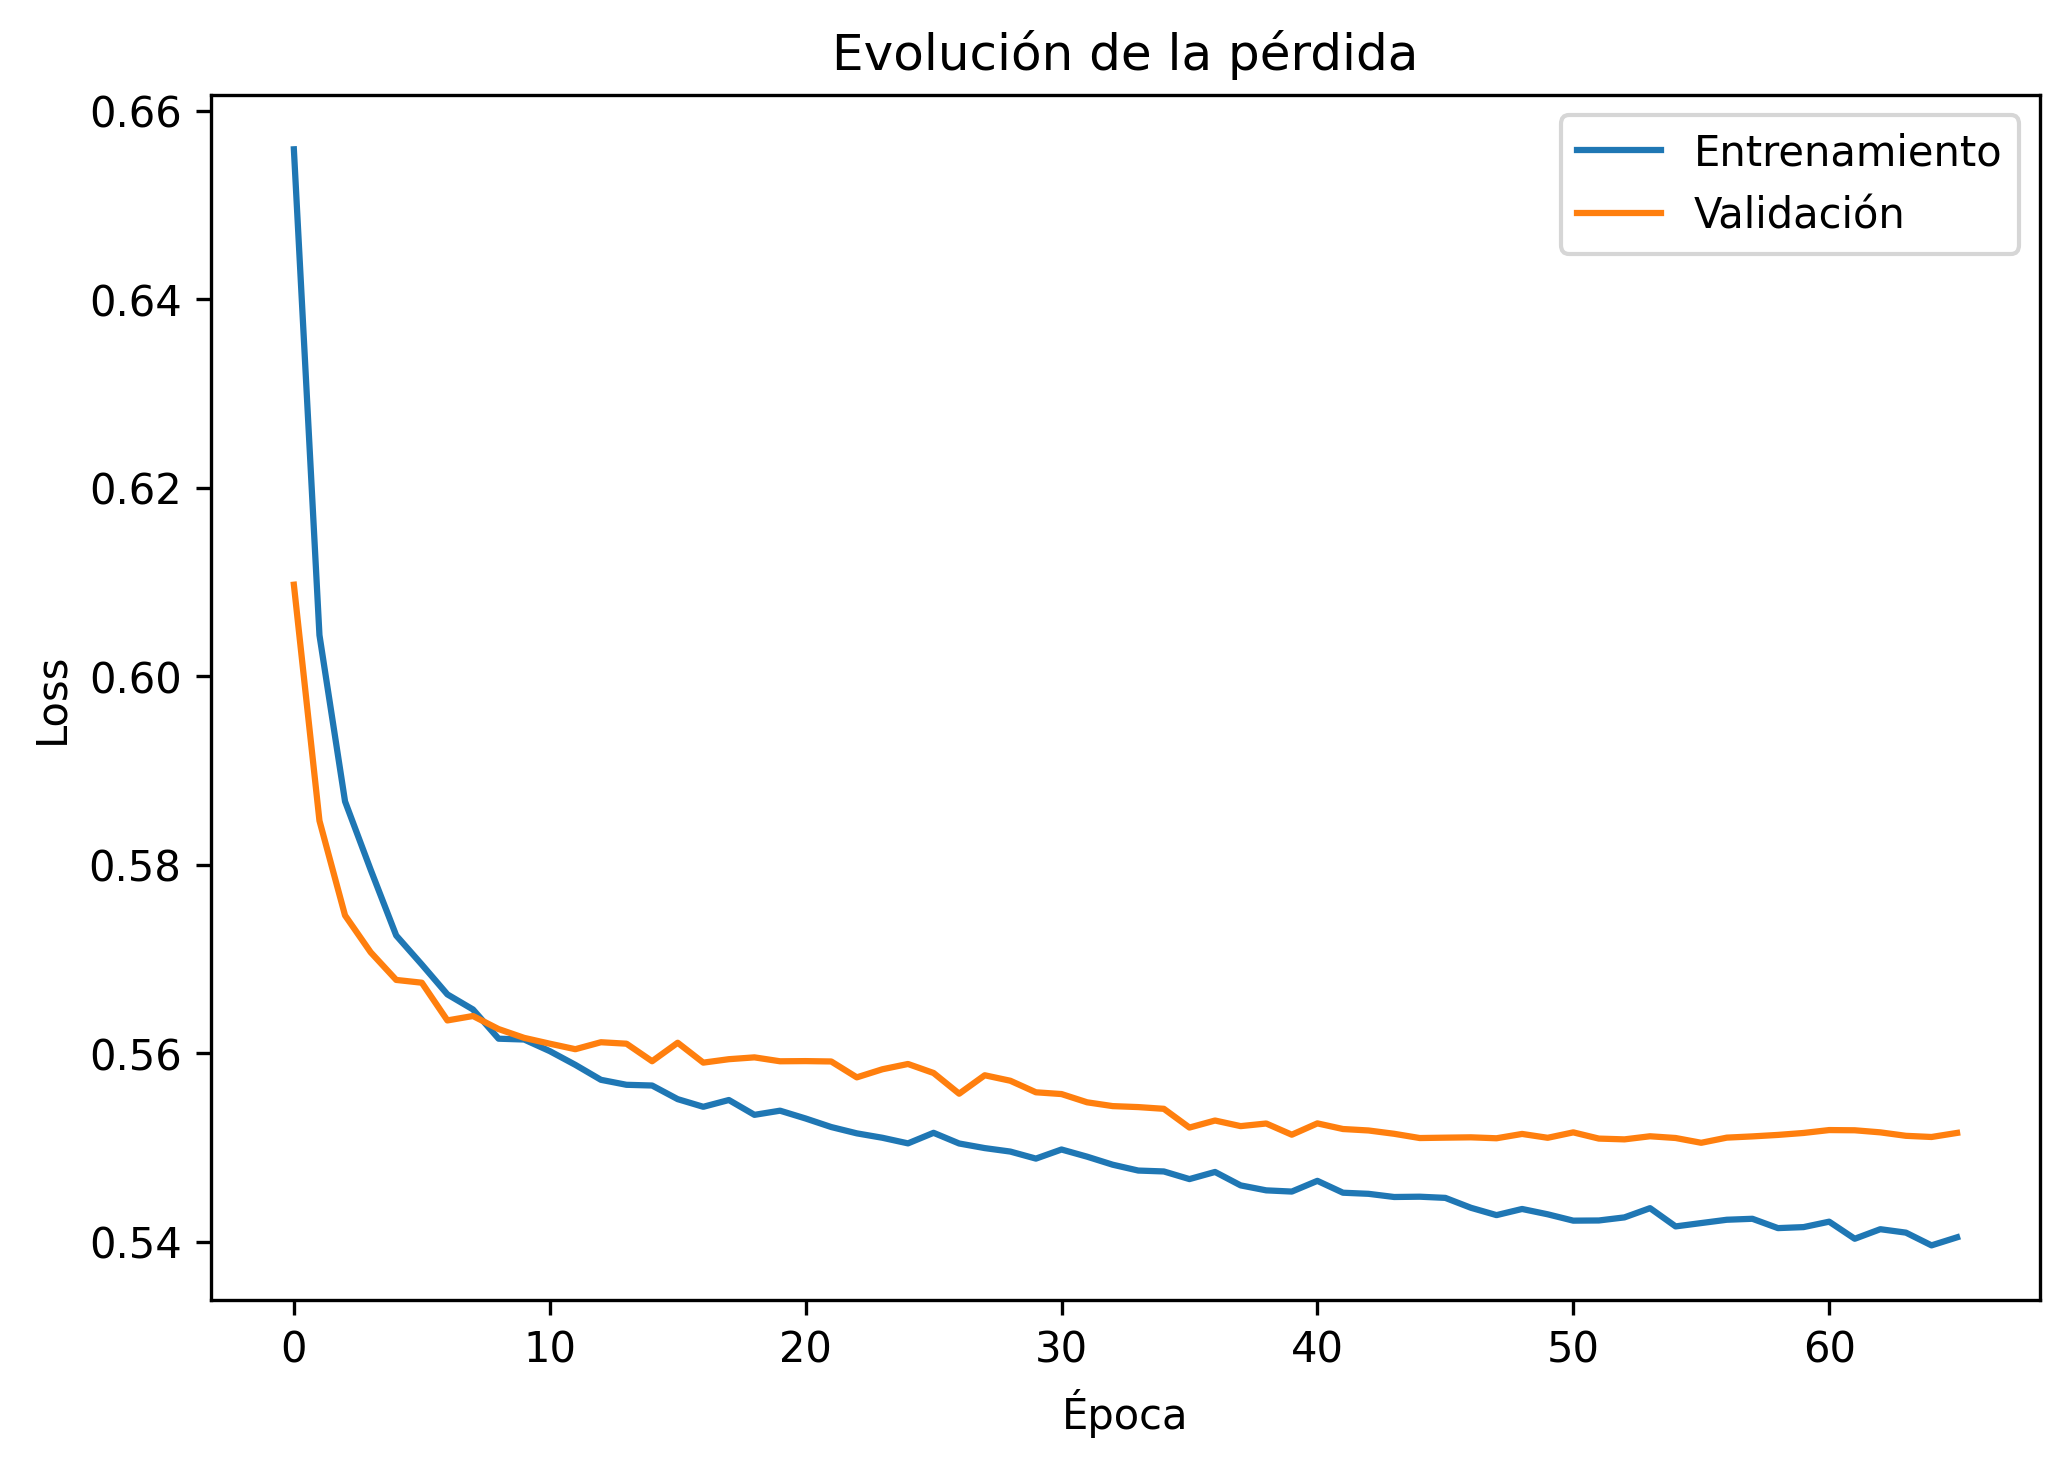

In [4]:
metricas, matriz = verificar_predicciones()
display(metricas)
display(pd.DataFrame(matriz, index=["Real 0", "Real 1"], columns=["Predicho 0", "Predicho 1"]))
print((RESULTADOS / "classification_report.txt").read_text(encoding="utf-8"))
for nombre in ["matriz_confusion.png", "curva_roc.png", "curva_accuracy.png", "curva_loss.png"]:
    display(Image(filename=str(RESULTADOS / "figuras" / nombre)))

Las métricas de precision, recall y F1 corresponden a `cardio=1`, con umbral 0.5. ROC-AUC utiliza probabilidades, no clases predichas.